Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


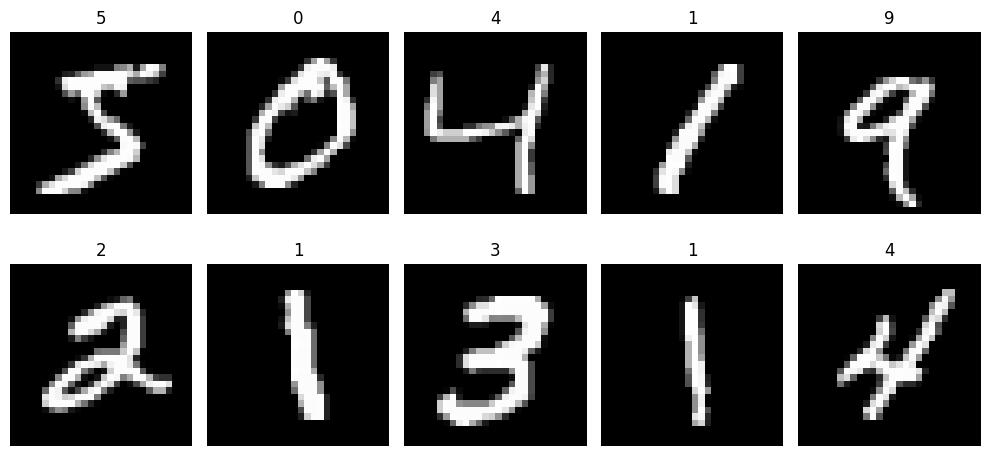


MLP MODEL SUMMARY


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 28, 28)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │         401,920 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 535,818 (2.04 MB)

 Trainable params: 535,818 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)


========== TRAINING MLP ==========
Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 15ms/step - accuracy: 0.1187 - loss: 2.3071 - val_accuracy: 0.4927 - val_loss: 2.0453
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.1291 - loss: 2.2939 - val_accuracy: 0.5650 - val_loss: 1.9629
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.1337 - loss: 2.2924 - val_accuracy: 0.5598 - val_loss: 2.0140
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.1347 - loss: 2.2919 - val_accuracy: 0.6548 - val_loss: 1.9144
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.1365 - loss: 2.2913 - val_accuracy: 0.6907 - val_loss: 1.7695
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.1423 - loss: 2.2858 - val_accuracy: 0.6983 - val_loss: 1.8197
Epoch 7/10
689/844 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.1353 - loss: 2.2905

In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models

# ==========================================
# 1. LOAD MNIST DATASET FROM NPZ
# ==========================================

data = np.load("mnist.npz")

x_train = data["x_train"]
y_train = data["y_train"]

x_test = data["x_test"]
y_test = data["y_test"]

# Normalize images
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten labels
y_train = y_train.flatten()
y_test = y_test.flatten()

# Handle one-hot encoded labels if present
if y_train.ndim > 1:
    y_train = np.argmax(y_train, axis=1)

if y_test.ndim > 1:
    y_test = np.argmax(y_test, axis=1)

class_names = [
    "0", "1", "2", "3", "4",
    "5", "6", "7", "8", "9"
]

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

# Add channel dimension for CNN
x_train_cnn = x_train.reshape(-1, 28, 28, 1)
x_test_cnn = x_test.reshape(-1, 28, 28, 1)


# ==========================================
# 2. VISUALIZE DATASET
# ==========================================

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()


# ==========================================
# 3. DATA AUGMENTATION
# ==========================================

def create_augmentation():
    return models.Sequential([
        layers.RandomRotation(0.05),
        layers.RandomTranslation(0.1, 0.1)
    ])


# ==========================================
# 4. BUILD MLP MODEL
# ==========================================

mlp_model = models.Sequential([
    layers.Input(shape=(28, 28)),

    create_augmentation(),

    layers.Flatten(),

    layers.Dense(512, activation="relu"),
    layers.Dense(256, activation="relu"),

    layers.Dense(10)
])

mlp_model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=["accuracy"]
)

print("\nMLP MODEL SUMMARY")
mlp_model.summary()


# ==========================================
# 5. BUILD CNN MODEL
# ==========================================

cnn_model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    create_augmentation(),

    # First convolution layer
    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    # Second convolution layer
    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    # Fully connected layers
    layers.Flatten(),

    layers.Dense(128, activation="relu"),

    layers.Dense(10)
])

cnn_model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=["accuracy"]
)

print("\nCNN MODEL SUMMARY")
cnn_model.summary()


# ==========================================
# 6. TRAIN BOTH MODELS
# ==========================================

epochs = 10
batch_size = 64

print("\n========== TRAINING MLP ==========")

mlp_history = mlp_model.fit(
    x_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.1,
    verbose=1
)

print("\n========== TRAINING CNN ==========")

cnn_history = cnn_model.fit(
    x_train_cnn,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.1,
    verbose=1
)


# ==========================================
# 7. EVALUATE MODELS
# ==========================================

mlp_loss, mlp_accuracy = mlp_model.evaluate(
    x_test, y_test, verbose=0
)

cnn_loss, cnn_accuracy = cnn_model.evaluate(
    x_test_cnn, y_test, verbose=0
)

print("\n========== MODEL COMPARISON ==========")

print(f"MLP Test Accuracy: {mlp_accuracy * 100:.2f}%")
print(f"CNN Test Accuracy: {cnn_accuracy * 100:.2f}%")

print(f"MLP Test Loss: {mlp_loss:.4f}")
print(f"CNN Test Loss: {cnn_loss:.4f}")


# ==========================================
# 8. ACCURACY COMPARISON GRAPH
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    mlp_history.history["accuracy"],
    label="MLP Training Accuracy"
)

plt.plot(
    cnn_history.history["accuracy"],
    label="CNN Training Accuracy"
)

plt.plot(
    mlp_history.history["val_accuracy"],
    label="MLP Validation Accuracy"
)

plt.plot(
    cnn_history.history["val_accuracy"],
    label="CNN Validation Accuracy"
)

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("MLP vs CNN Accuracy")

plt.legend()
plt.grid()
plt.show()


# ==========================================
# 9. LOSS COMPARISON GRAPH
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    mlp_history.history["loss"],
    label="MLP Training Loss"
)

plt.plot(
    cnn_history.history["loss"],
    label="CNN Training Loss"
)

plt.plot(
    mlp_history.history["val_loss"],
    label="MLP Validation Loss"
)

plt.plot(
    cnn_history.history["val_loss"],
    label="CNN Validation Loss"
)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("MLP vs CNN Loss")

plt.legend()
plt.grid()
plt.show()


# ==========================================
# 10. PREDICT TEST IMAGES USING CNN
# ==========================================

predictions = cnn_model.predict(
    x_test_cnn[:10],
    verbose=0
)

probabilities = tf.nn.softmax(predictions, axis=1)

plt.figure(figsize=(12, 6))

for i in range(10):

    predicted_class = np.argmax(probabilities[i])

    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i], cmap="gray")

    plt.title(
        f"Actual: {class_names[y_test[i]]}\n"
        f"Predicted: {class_names[predicted_class]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


# ==========================================
# 11. SAVE TRAINED MODELS
# ==========================================

mlp_model.save("mnist_mlp.keras")
cnn_model.save("mnist_cnn.keras")

print("\nModels saved successfully!")

print("\n========== FINAL RESULTS ==========")

if cnn_accuracy > mlp_accuracy:
    print("CNN performed better than MLP.")
elif mlp_accuracy > cnn_accuracy:
    print("MLP performed better than CNN.")
else:
    print("Both models achieved equal accuracy.")
